# 3. ¿De qué está hecha la pobreza en el Chocó?

El IPM es un solo número, pero detrás hay 15 privaciones distintas. Saber **cuáles pesan más** dice dónde
actuar: no es lo mismo un municipio pobre por falta de acueducto que uno pobre por bajo logro educativo.

> **Nota de método.** Con porcentajes municipales no se puede calcular la contribución exacta del método
> Alkire-Foster (eso requiere saber qué privaciones tiene a la vez cada hogar). Aquí se usa el
> **aporte de cada indicador al puntaje promedio de privación** (peso × % de hogares privados), que es la
> mejor aproximación con datos agregados. Para el departamento completo, el notebook 4 usa las
> contribuciones oficiales del DANE.

In [1]:
# Preparación: ubica la carpeta del repo y carga el paquete del estudio
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
for _ in range(5):
    if (RAIZ / "src" / "pobreza").exists():
        break
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pobreza import datos, ipm
from pobreza.config import ETIQUETAS, IPM_INDICADORES, DIMENSIONES, PACIFICO, REPORTES
from pobreza.graficos import CHOCO, RESTO, ACENTO, NEUTRO, DIMENSION_COLORES, estilo, guardar, fuente

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.max_columns", 40)

In [2]:
base = datos.base_municipal()
ind = ipm.indicadores_presentes(base)
etq = [ETIQUETAS[i] for i in ind]
choco = base[base.es_choco].set_index("municipio").sort_values("ipm", ascending=False)
peso_pob = base["poblacion_total"] if "poblacion_total" in base else None
print(f"{len(ind)} indicadores disponibles")

15 indicadores disponibles


## 3.1 Chocó contra el resto del país, indicador por indicador

Promedios ponderados por población (cuenta a las personas, no a los municipios).

,Chocó,Resto del país,Diferencia (pp),Razón
Pisos inadecuados,6.5,8.3,-1.8,0.8
Barreras de acceso a salud,5.1,4.4,0.7,1.1
Trabajo infantil,2.2,1.1,1.0,1.9
Inasistencia escolar,8.1,4.0,4.1,2.0
Hacinamiento crítico,14.5,9.9,4.6,1.5
Barreras primera infancia,8.0,2.2,5.8,3.6
Sin aseguramiento en salud,23.4,17.0,6.4,1.4
Empleo informal,92.8,80.7,12.1,1.2
Rezago escolar,28.6,15.8,12.8,1.8
Paredes inadecuadas,18.7,4.0,14.7,4.7


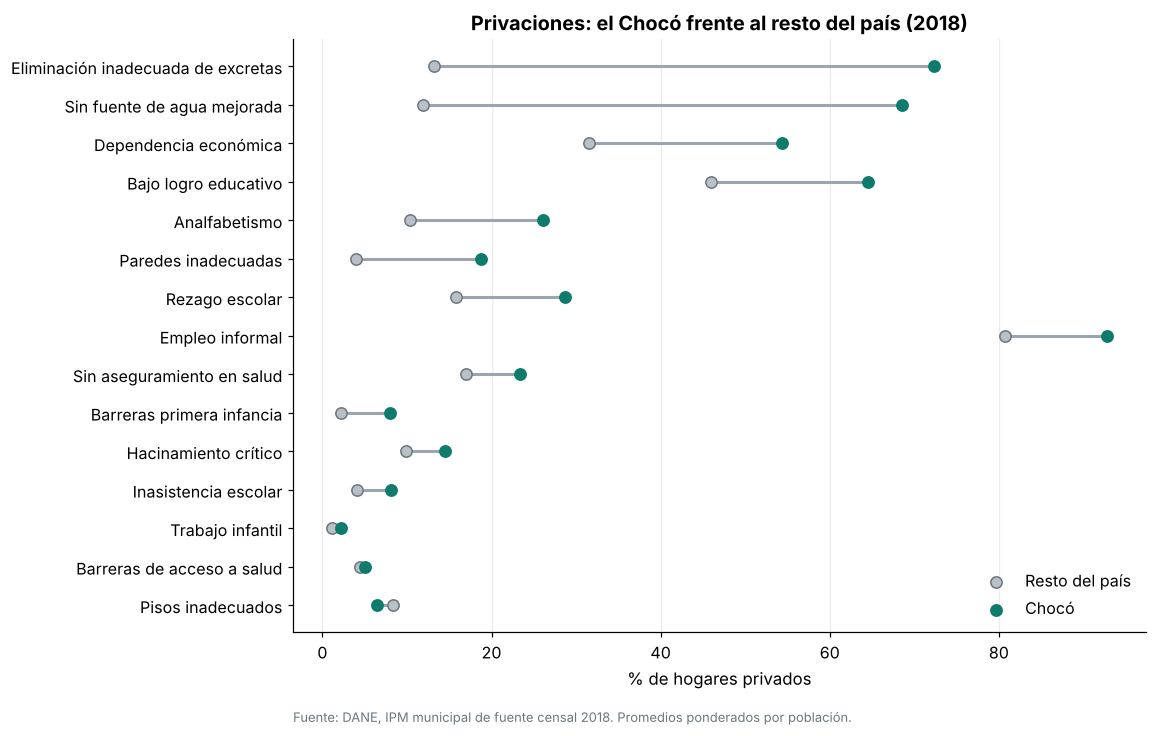

In [3]:
br = ipm.brecha(base, ind, base["es_choco"], peso_pob).rename(columns={"Grupo": "Chocó", "Resto": "Resto del país"})
br.index = etq
br = br.sort_values("Diferencia (pp)")
display(br.round(1))

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(br))
ax.hlines(y, br["Resto del país"], br["Chocó"], color="#9aa5b1", lw=2)
ax.scatter(br["Resto del país"], y, color=RESTO, s=55, label="Resto del país", zorder=3, edgecolor="#6b7680")
ax.scatter(br["Chocó"], y, color=CHOCO, s=55, label="Chocó", zorder=3)
ax.set_yticks(y, br.index)
ax.set(xlabel="% de hogares privados", title="Privaciones: el Chocó frente al resto del país (2018)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fuente(ax, "DANE, IPM municipal de fuente censal 2018. Promedios ponderados por población.")
guardar(fig, "03_brecha_indicadores")
plt.show()

## 3.2 Mapa de calor: los 30 municipios × 15 privaciones

Cada fila es un municipio (ordenados de más a menos pobre) y cada columna una privación.
Los colores más oscuros son más hogares privados.

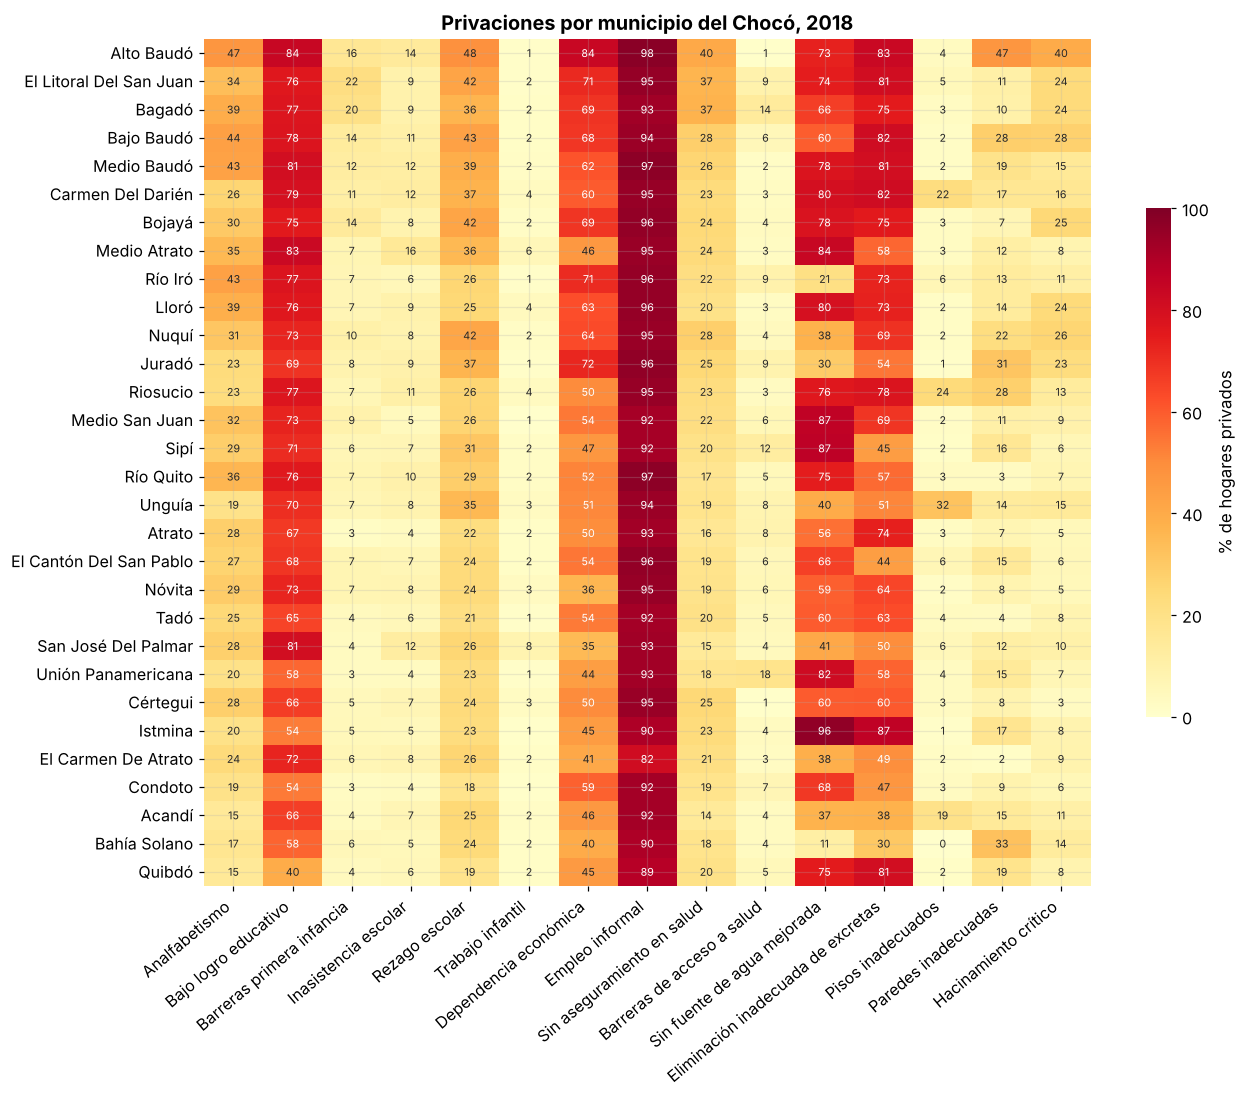

In [4]:
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(choco[ind].set_axis(etq, axis=1), cmap="YlOrRd", vmin=0, vmax=100, annot=True, fmt=".0f",
            annot_kws={"size": 7}, cbar_kws={"label": "% de hogares privados", "shrink": 0.6}, ax=ax)
ax.set(xlabel="", ylabel="", title="Privaciones por municipio del Chocó, 2018")
plt.xticks(rotation=40, ha="right")
guardar(fig, "03_mapa_calor")
plt.show()

## 3.3 ¿Qué dimensión pesa más en cada municipio?

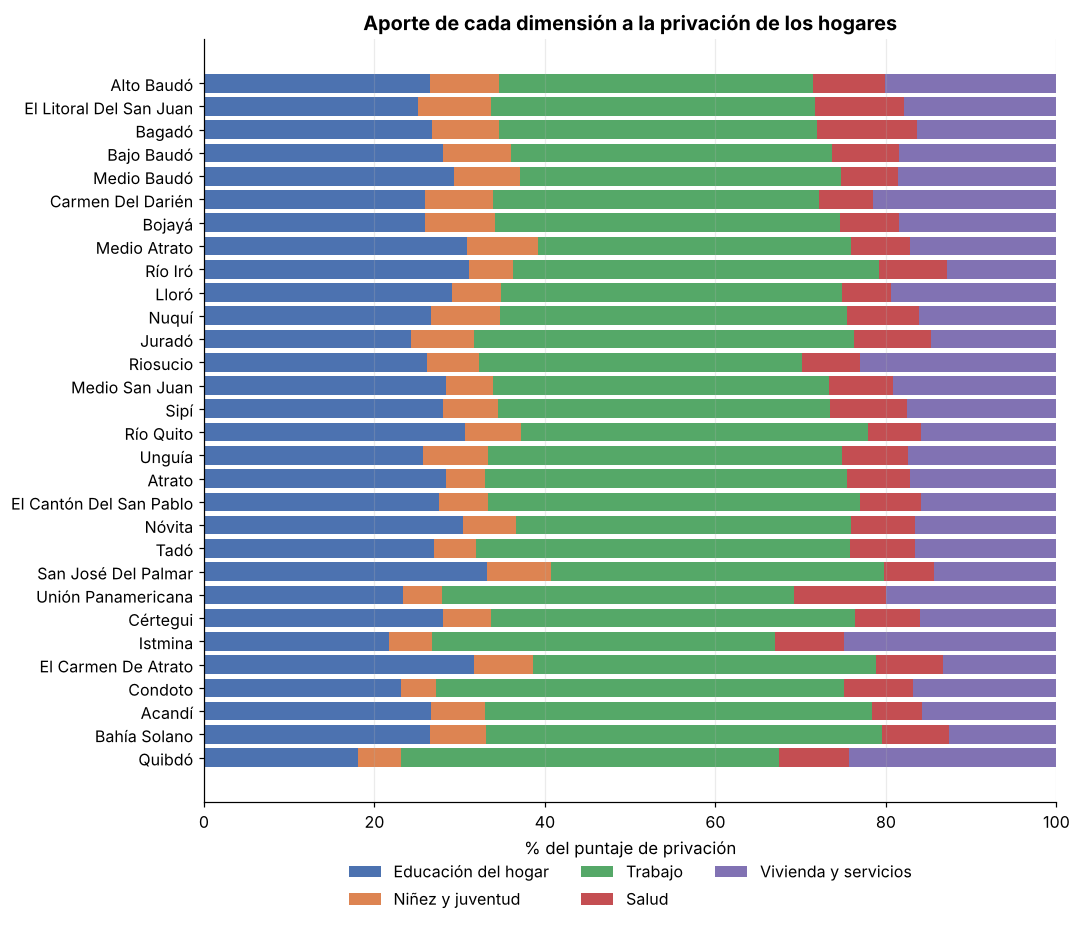

,Chocó,Resto del país
Educación del hogar,27.1,30.3
Niñez y juventud,6.5,4.9
Trabajo,40.9,46.9
Salud,7.8,7.2
Vivienda y servicios,17.6,10.7


In [5]:
contrib = ipm.contribucion_agregado(choco, por="dimension")
contrib = contrib.loc[choco.index]
fig, ax = plt.subplots(figsize=(10, 9))
izq = np.zeros(len(contrib))
for dim in contrib.columns:
    ax.barh(contrib.index, contrib[dim], left=izq, color=DIMENSION_COLORES[dim], label=dim)
    izq += contrib[dim].values
ax.invert_yaxis()
ax.set(xlabel="% del puntaje de privación", xlim=(0, 100),
       title="Aporte de cada dimensión a la privación de los hogares")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.06))
ax.grid(axis="y", visible=False)
guardar(fig, "03_aporte_dimensiones")
plt.show()

tot_choco = ipm.contribucion_agregado(base[base.es_choco], por="dimension").mean()
tot_resto = ipm.contribucion_agregado(base[~base.es_choco], por="dimension").mean()
display(pd.DataFrame({"Chocó": tot_choco, "Resto del país": tot_resto}).round(1))

## 3.4 ¿Qué privaciones van juntas?

Si dos privaciones están muy correlacionadas entre municipios, probablemente responden a la misma causa
(por ejemplo, ruralidad dispersa), y una misma política puede mover las dos.

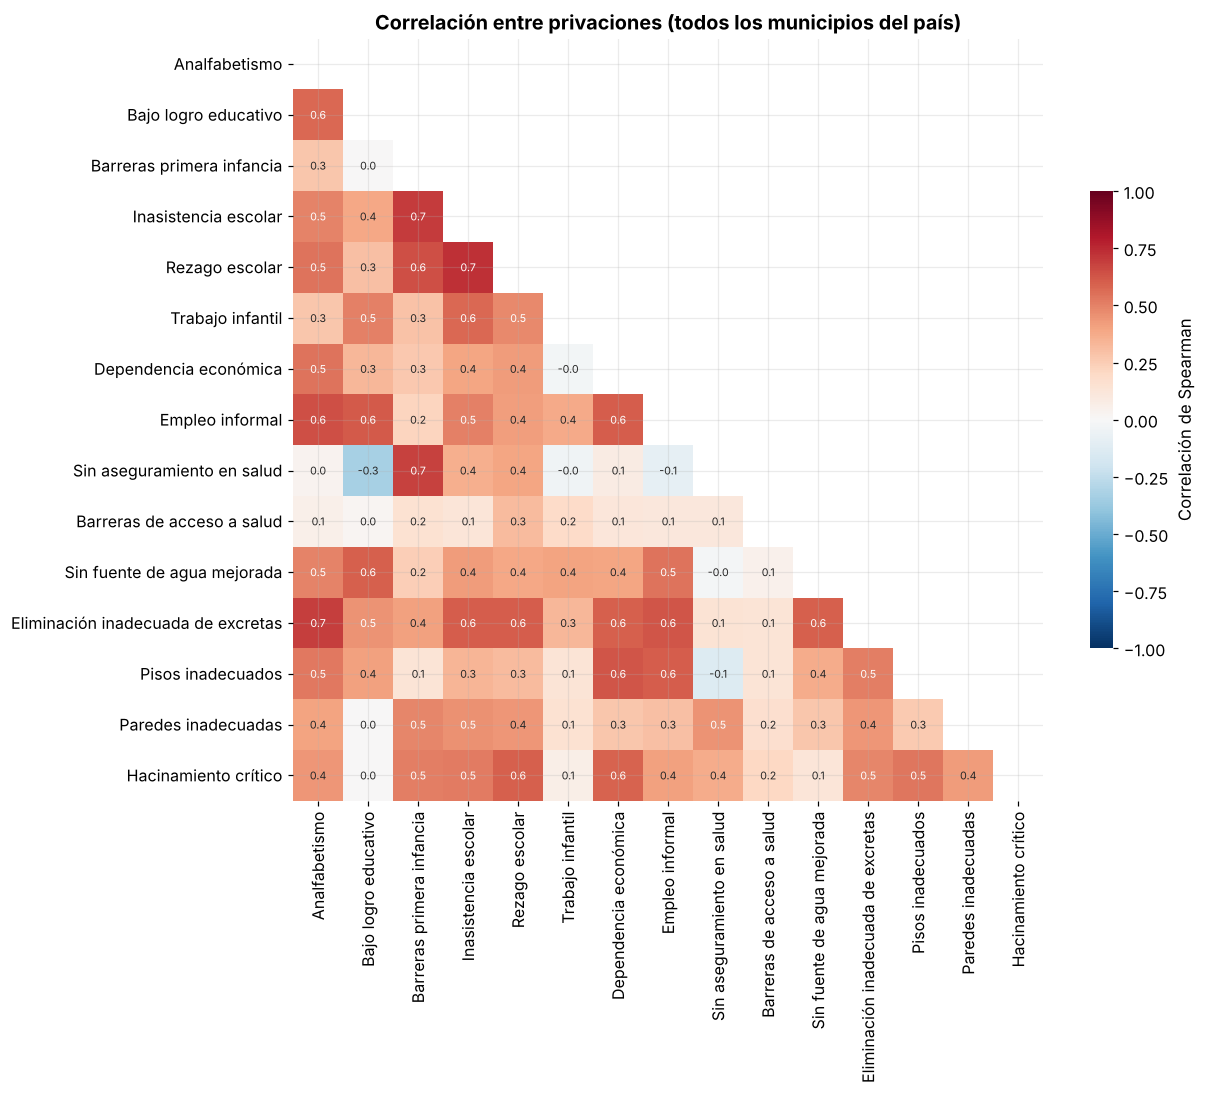

In [6]:
corr = base[ind].corr(method="spearman")
corr.index = corr.columns = etq
fig, ax = plt.subplots(figsize=(11, 9))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Correlación de Spearman", "shrink": 0.6}, ax=ax)
ax.set_title("Correlación entre privaciones (todos los municipios del país)")
guardar(fig, "03_correlaciones")
plt.show()

## 3.5 Tipologías de municipios

Se agrupan **todos los municipios del país** según su perfil de privaciones (no según su nivel total), con
un agrupamiento jerárquico sobre los indicadores estandarizados. Luego se mira en qué grupos caen los del
Chocó. Esto ayuda a encontrar municipios de otras regiones con problemas parecidos (y de quienes aprender).

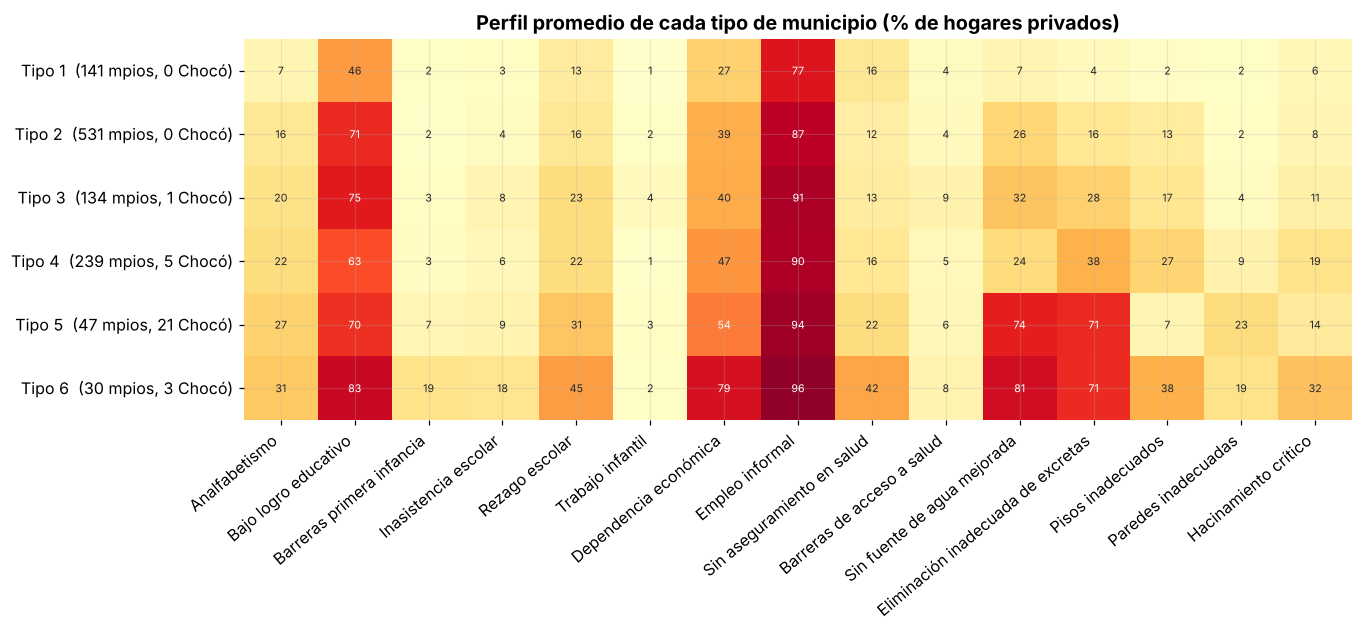

,municipio,ipm,tipo
0,San José Del Palmar,59.1,Tipo 3
1,Bahía Solano,46.6,Tipo 4
2,Acandí,51.4,Tipo 4
3,El Carmen De Atrato,54.0,Tipo 4
4,Unguía,63.4,Tipo 4
5,Río Iró,75.1,Tipo 4
6,Quibdó,44.4,Tipo 5
7,Condoto,53.2,Tipo 5
8,Istmina,55.1,Tipo 5
9,Cértegui,55.9,Tipo 5


In [7]:
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.preprocessing import StandardScaler

X = base[ind].fillna(base[ind].median())
Z = linkage(StandardScaler().fit_transform(X), method="ward")
n_grupos = 6
base["tipo"] = fcluster(Z, n_grupos, criterion="maxclust")

perfil = base.groupby("tipo")[ind + ["ipm"]].mean()
perfil["municipios"] = base.groupby("tipo").size()
perfil["del Chocó"] = base.groupby("tipo")["es_choco"].sum()
perfil = perfil.sort_values("ipm")
perfil.index = [f"Tipo {i + 1}" for i in range(len(perfil))]
mapa_tipos = dict(zip(base.groupby("tipo")["ipm"].mean().sort_values().index, perfil.index))
base["tipo"] = base["tipo"].map(mapa_tipos)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(perfil[ind].set_axis(etq, axis=1), cmap="YlOrRd", vmin=0, vmax=100, annot=True, fmt=".0f",
            annot_kws={"size": 7}, cbar=False, ax=ax)
ax.set_yticklabels([f"{t}  ({int(r.municipios)} mpios, {int(r['del Chocó'])} Chocó)"
                    for t, r in perfil.iterrows()], rotation=0)
ax.set(xlabel="", ylabel="", title="Perfil promedio de cada tipo de municipio (% de hogares privados)")
plt.xticks(rotation=40, ha="right")
guardar(fig, "03_tipologias")
plt.show()

display(base.loc[base.es_choco, ["municipio", "ipm", "tipo"]].sort_values(["tipo", "ipm"]).reset_index(drop=True))
base[["cod_mpio", "tipo"]].to_csv(REPORTES / "tipologias_municipios.csv", index=False)

## Para llevar

- Las brechas más grandes con el resto del país aparecen donde el gráfico 3.1 muestra las líneas más largas;
  esas son las privaciones donde el Chocó está más lejos del país, no necesariamente las más frecuentes.
- La composición cambia entre municipios: en unos domina vivienda y servicios, en otros educación.
  Una política "para el Chocó" sin diferenciar por municipio se queda corta.
- Las tipologías muestran con qué municipios del país comparte problemas cada municipio chocoano.